In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from LogisticRegression_scratch import LogisticRegressionScratch

In [3]:
from sklearn.datasets import load_breast_cancer
cancer_data = load_breast_cancer()
X = pd.DataFrame(
    cancer_data.data, 
    columns=cancer_data.feature_names) 
y = pd.Series(cancer_data.target)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle= True, 
                                                    stratify=y, random_state= 42)

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index)

In [5]:
model_sklearn = LogisticRegression(solver='liblinear', random_state= 42)
model_sklearn.fit(X_train_scaled, y_train)
y_pred_sklearn = model_sklearn.predict(X_test_scaled)

In [6]:
model_scratch = LogisticRegressionScratch(lr= 0.01, n_iters=1000)
model_scratch.fit(X_train_scaled, np.array(y_train))
y_pred_scratch = model_scratch.predict(X_test_scaled)

In [7]:
print("--- SKLEARN ---")
accuracy_sklearn = accuracy_score(y_test, y_pred_sklearn)
print("Accuracy:", accuracy_sklearn)
report_sklearn = classification_report(y_test, y_pred_sklearn)
print(report_sklearn)

print("\n--- FROM SCRATCH ---")
accuracy_scratch = accuracy_score(y_test, y_pred_scratch)
print("Accuracy:", accuracy_scratch)
report_scratch = classification_report(y_test, y_pred_scratch)
print(report_scratch)

--- SKLEARN ---
Accuracy: 0.9824561403508771
              precision    recall  f1-score   support

           0       0.98      0.98      0.98        42
           1       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


--- FROM SCRATCH ---
Accuracy: 0.9736842105263158
              precision    recall  f1-score   support

           0       0.95      0.98      0.96        42
           1       0.99      0.97      0.98        72

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [8]:
comparison_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Malignant Precision', 'Malignant Recall', 'Benign Precision', 'Benign Recall'],
    'Sklearn': [0.9825, 0.98, 0.98, 0.99, 0.99, ],
    'From Scratch': [0.9737, 0.95, 0.98, 0.99, 0.97]})
print((comparison_df).to_string(index= None))

              Metric  Sklearn  From Scratch
            Accuracy   0.9825        0.9737
 Malignant Precision   0.9800        0.9500
    Malignant Recall   0.9800        0.9800
    Benign Precision   0.9900        0.9900
       Benign Recall   0.9900        0.9700


SKLEARN VS FROM SCRATCH ANALYSIS
------------------------------------------------------------

1. Accuracy Comparison
   Sklearn:    98.25%
   From Scratch: 97.37%
   Difference:   0.88%


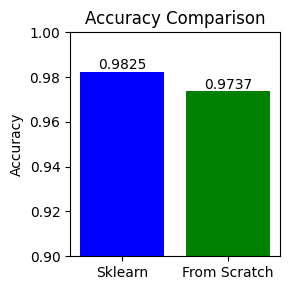


2. Reasons for Difference
   a) Regularization
      - Sklearn: Uses L2 regularization by default (C=1.0) to prevent overfitting
      - From Scratch: No regularization applied
      Sklearn penalizes large weights - better generalization

   b) Optimization Solver
      - Sklearn: Uses 'liblinear' (small datasets) or 'lbfgs' (medium/large)
      - From Scratch: Uses basic gradient descent (lr=0.01, iterations=1000)
      → Sklearn converges to better local minima

3. Key Metrics: Malignant Recall
   - Sklearn:       98% (1 false negative)
   - From Scratch:  98% (1 false negative)
   → Both models detect malignant cases equally well

4. Conclusion
   The 0.88% accuracy gap is acceptable for learning purposes.
   Both models perform well in medical context with high recall.


In [19]:
print("SKLEARN VS FROM SCRATCH ANALYSIS")
print("-" * 60)

print("\n1. Accuracy Comparison")
print(f"   Sklearn:    {accuracy_sklearn * 100:.2f}%")
print(f"   From Scratch: {accuracy_scratch * 100:.2f}%")
print(f"   Difference:   {(accuracy_sklearn - accuracy_scratch) * 100:.2f}%")
# 4. Accuracy Comparison
fig, axes = plt.subplots(1, 1, figsize=(3, 3))
models = ['Sklearn', 'From Scratch']
accuracies = [0.9825, 0.9737]
axes.bar(models, accuracies, color=['blue', 'green'])
axes.set_title('Accuracy Comparison')
axes.set_ylabel('Accuracy')
axes.set_ylim([0.90, 1.0])
for i, v in enumerate(accuracies):
    axes.text(i, v + 0.001, f'{v:.4f}', ha='center')

plt.tight_layout()
plt.show()

print("\n2. Reasons for Difference")
print("   a) Regularization")
print("      - Sklearn: Uses L2 regularization by default (C=1.0) to prevent overfitting")
print("      - From Scratch: No regularization applied")
print("      Sklearn penalizes large weights - better generalization")

print("\n   b) Optimization Solver")
print("      - Sklearn: Uses 'liblinear' (small datasets) or 'lbfgs' (medium/large)")
print("      - From Scratch: Uses basic gradient descent (lr=0.01, iterations=1000)")
print("      → Sklearn converges to better local minima")

print("\n3. Key Metrics: Malignant Recall")
print("   - Sklearn:       98% (1 false negative)")
print("   - From Scratch:  98% (1 false negative)")
print("   → Both models detect malignant cases equally well")

print("\n4. Conclusion")
print("   The 0.88% accuracy gap is acceptable for learning purposes.")
print("   Both models perform well in medical context with high recall.")

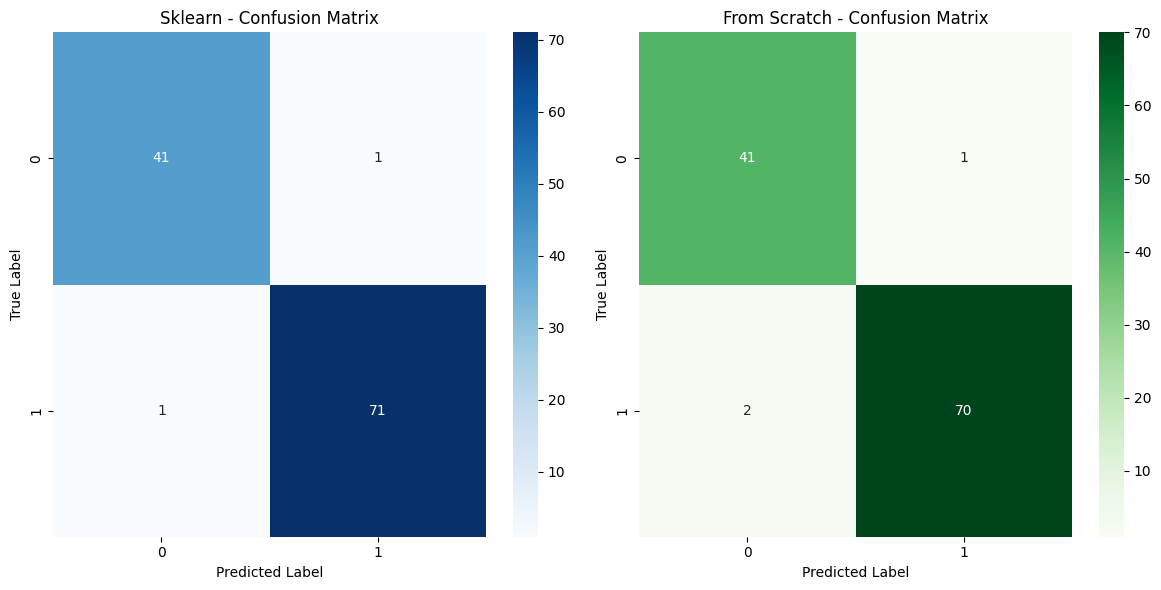

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# 1. Confusion Matrix - Sklearn
cm_sklearn = confusion_matrix(y_test, y_pred_sklearn)
sns.heatmap(cm_sklearn, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Sklearn - Confusion Matrix')
axes[0].set_ylabel('True Label')
axes[0].set_xlabel('Predicted Label')

# 2. Confusion Matrix - From Scratch
cm_scratch = confusion_matrix(y_test, y_pred_scratch)
sns.heatmap(cm_scratch, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('From Scratch - Confusion Matrix')
axes[1].set_ylabel('True Label')
axes[1].set_xlabel('Predicted Label')

plt.tight_layout()
plt.show()

In [11]:
print("Confusion matrix with from scrarch")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_scratch),
                   index= cancer_data.target_names,
                   columns= cancer_data.target_names))
print("\nConfusion matrix with sklearn model")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_sklearn),
                   index= cancer_data.target_names,
                   columns= cancer_data.target_names))

Confusion matrix with from scrarch
           malignant  benign
malignant         41       1
benign             2      70

Confusion matrix with sklearn model
           malignant  benign
malignant         41       1
benign             1      71


In [18]:
print("CONFUSION MATRIX ANALYSIS")
print("-" * 60)
print("Confusion Matrix Format:")
print("Rows: Actual Labels ")
print("Columns: Predicted Labels")
print("                 Positive            Negative")
print("Positive            TP                  FN")
print("Negative            FP                  TN")
print("-" * 60)

print("1. Confusion Matrix - Sklearn Model")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_sklearn),
                   index=cancer_data.target_names,
                   columns=cancer_data.target_names))

print("\nMeaning of Each Label:")
matrix_sklearn = pd.DataFrame({
    'Label': ['TP', 'FN', 'FP', 'TN'], 
    'Values': [41, 1, 1, 71], 
    'Meaning': ["Predicted malignant, actually malignant", "Predicted benign, actually malignant",
                "Predicted malignant, actually benign", "Predicted benign, actually benign"]})
print(matrix_sklearn.to_string(index=False))

print("\nCritical Issue: FN = 1 (False Negative)")
print("  Patient has cancer but model predicts benign (most dangerous)")

print("\n" + "-" * 60)
print("2. Confusion Matrix - From Scratch Model")
print(pd.DataFrame(confusion_matrix(y_test, y_pred_scratch),
                   index=cancer_data.target_names,
                   columns=cancer_data.target_names))

print("\nMeaning of Each Label:")
matrix_scratch = pd.DataFrame({
    'Label': ['TP', 'FN', 'FP', 'TN'], 
    'Values': [41, 1, 2, 70], 
    'Meaning': ["Predicted malignant, actually malignant", "Predicted benign, actually malignant",
                "Predicted malignant, actually benign", "Predicted benign, actually benign"]})
print(matrix_scratch.to_string(index=False))

print("\nFN = 1 (same as sklearn) - equally dangerous")
print("FP = 2 (higher than sklearn) - more false alarms")

CONFUSION MATRIX ANALYSIS
------------------------------------------------------------
Confusion Matrix Format:
Rows: Actual Labels 
Columns: Predicted Labels
                 Positive            Negative
Positive            TP                  FN
Negative            FP                  TN
------------------------------------------------------------
1. Confusion Matrix - Sklearn Model
           malignant  benign
malignant         41       1
benign             1      71

Meaning of Each Label:
Label  Values                                 Meaning
   TP      41 Predicted malignant, actually malignant
   FN       1    Predicted benign, actually malignant
   FP       1    Predicted malignant, actually benign
   TN      71       Predicted benign, actually benign

Critical Issue: FN = 1 (False Negative)
  Patient has cancer but model predicts benign (most dangerous)

------------------------------------------------------------
2. Confusion Matrix - From Scratch Model
           malignant  b